# 01 · Exploratory Analysis & Hypothesis Testing
**Insurance Claims Fraud Detection: motor insurance portfolio, 2022–2025**

### Business problem
A motor insurer settles ~4,000–5,000 claims a year. Its Special Investigation Unit (SIU) can only investigate **~10% of claims**, and today it picks them with a **rules-based red-flag score**. Confirmed fraud is ~10% of claims. Even so, money is still being paid out on fraudulent claims.

**Question:** *Which claims should the SIU investigate to stop the most fraud value with the same team?*

### Hypotheses (framed before looking at the data)
| # | Hypothesis | Why it might be true |
|---|---|---|
| H1 | Claims made soon after policy purchase are riskier | Buying cover for damage that already happened |
| H2 | Late-reported claims are riskier | Time to stage evidence / inflate estimates |
| H3 | Night-time major losses without a police report are riskier | Fewer independent witnesses / records |
| H4 | Repeat claimants are riskier | Opportunistic or serial behaviour |
| H5 | Fraud concentrates in a few garages and agents | Collusive repair-shop / intermediary networks |
| H6 | Fraudulent claims are larger relative to insured value | Bill padding |

Each hypothesis is tested with SQL against the claims database and a **chi-square / Mann-Whitney test** for statistical significance.

In [1]:
import sqlite3, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

sys.path.insert(0, "../src")
import plots as P
P.setup_style()
pd.set_option("display.float_format", "{:,.2f}".format)

con = sqlite3.connect("../data/insurance_claims.db")   # built by src/build_database.py
FIG = "../reports/figures/"

def q(sql):
    return pd.read_sql(sql, con)

## 1. Portfolio overview

In [2]:
overview = q('''
SELECT COUNT(*)                                       AS claims,
       ROUND(100.0 * AVG(is_fraud), 2)                AS fraud_rate_pct,
       ROUND(SUM(total_claim_amount) / 1e7, 1)        AS claimed_cr,
       ROUND(SUM(CASE WHEN is_fraud = 1 THEN total_claim_amount END) / 1e7, 1) AS fraud_claimed_cr,
       ROUND(SUM(CASE WHEN is_fraud = 1 THEN settled_amount END) / 1e7, 1)     AS fraud_paid_out_cr
FROM claims''')
overview

,claims,fraud_rate_pct,claimed_cr,fraud_claimed_cr,fraud_paid_out_cr
0,16810,10.17,273.90,37.70,12.70


In [3]:
# Base dataset for the hypothesis tests: the clean denormalised view + red flags
base = q('''SELECT b.*, f.red_flag_score, f.rf_repeat_claimant
            FROM v_claim_base b JOIN claim_red_flags f USING (claim_id)''')
BASE_RATE = 100 * base.is_fraud.mean()

def chi2_test(df, group_col):
    table = pd.crosstab(df[group_col], df.is_fraud)
    chi2, p, dof, _ = stats.chi2_contingency(table)
    return p

print(f"{len(base):,} claims | base fraud rate {BASE_RATE:.1f}%")
paid = q("SELECT AVG(settled_amount > 0) AS share FROM claims WHERE is_fraud = 1").share[0]
print(f"{paid:.0%} of confirmed-fraud claims were still paid in full or in part")

16,810 claims | base fraud rate 10.2%
40% of confirmed-fraud claims were still paid in full or in part


**Read-out:** about one in ten claims is confirmed fraud. Several crore of fraudulent claims were still paid out (fully or partly). That leakage is what the project goes after.

## 2. H1 & H2: Timing: early claims and late reporting

H1 chi-square p-value: 2.5e-131
H2 chi-square p-value: 4.2e-97


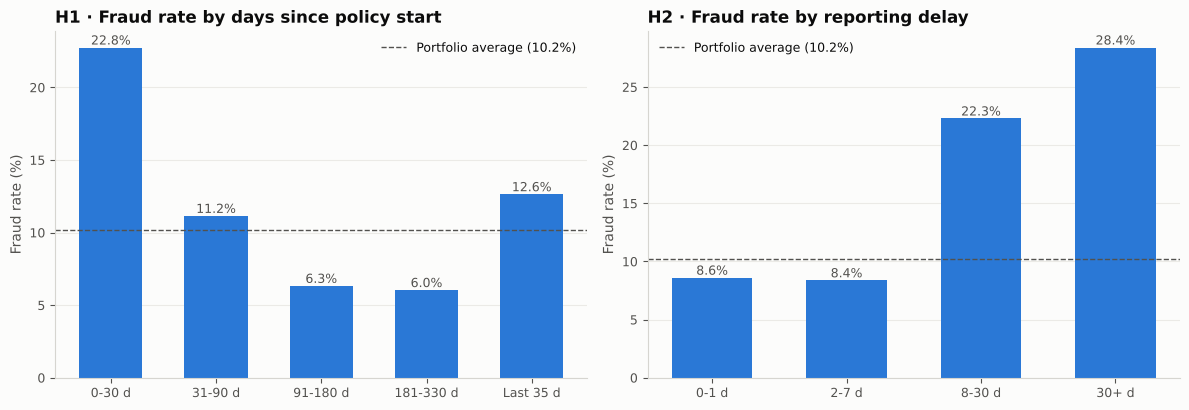

In [4]:
base["policy_age_bucket"] = pd.cut(base.days_policy_to_incident, [-1, 30, 90, 180, 330, 400],
                                   labels=["0-30 d", "31-90 d", "91-180 d", "181-330 d", "Last 35 d"])
base["delay_bucket"] = pd.cut(base.report_delay_days, [-1, 1, 7, 30, 1000],
                              labels=["0-1 d", "2-7 d", "8-30 d", "30+ d"])
h1 = base.groupby("policy_age_bucket", observed=True).is_fraud.agg(["size", "mean"])
h2 = base.groupby("delay_bucket", observed=True).is_fraud.agg(["size", "mean"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
P.bar_rate(axes[0], h1.index.astype(str), 100 * h1["mean"], "H1 · Fraud rate by days since policy start", BASE_RATE)
P.bar_rate(axes[1], h2.index.astype(str), 100 * h2["mean"], "H2 · Fraud rate by reporting delay", BASE_RATE)
for ax in axes: ax.set_ylabel("Fraud rate (%)")
fig.tight_layout(); fig.savefig(FIG + "01_timing_red_flags.png")

print(f"H1 chi-square p-value: {chi2_test(base, 'policy_age_bucket'):.1e}")
print(f"H2 chi-square p-value: {chi2_test(base.dropna(subset=['delay_bucket']), 'delay_bucket'):.1e}")

**Read-out:**
- **H1 supported.** Claims in the first 30 days of a policy are fraudulent at **~2–3× the portfolio rate**. There's a second, smaller bump in the last weeks before expiry ("use it before you lose it").
- **H2 supported.** Claims reported more than a week late are ~2.5–3× riskier.

## 3. H3: Night-time major losses without a police report

H3 chi-square p-value: 7.2e-36


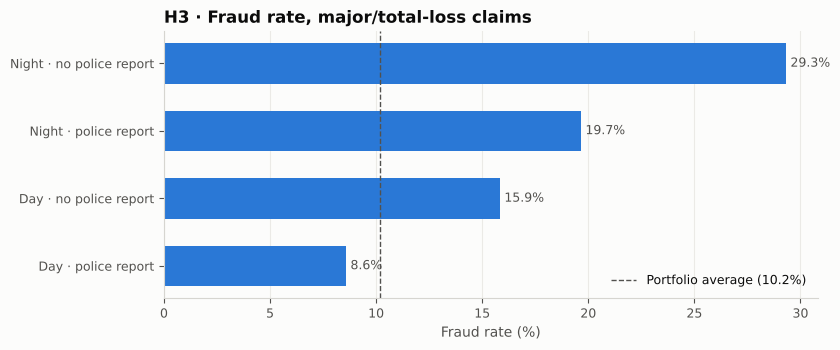

,claims,fraud_rate
segment,,
Night · no police report,167,0.29
Night · police report,869,0.20
Day · no police report,864,0.16
Day · police report,4905,0.09


In [5]:
major = base[base.incident_severity.isin(["Major", "Total Loss"]) & base.incident_hour.notna()].copy()
major["segment"] = np.where(major.incident_hour <= 4, "Night", "Day") + " · " + \
                   np.where(major.police_report_filed == 1, "police report", "no police report")
h3 = major.groupby("segment").is_fraud.agg(["size", "mean"]).sort_values("mean", ascending=False)

fig, ax = plt.subplots(figsize=(8.5, 3.6))
P.bar_rate(ax, h3.index, 100 * h3["mean"], "H3 · Fraud rate, major/total-loss claims", BASE_RATE, horizontal=True)
ax.set_xlabel("Fraud rate (%)")
fig.tight_layout(); fig.savefig(FIG + "02_night_no_police.png")
print(f"H3 chi-square p-value: {chi2_test(major, 'segment'):.1e}")
h3.rename(columns={"size": "claims", "mean": "fraud_rate"})

**Read-out: H3 supported.** Night-time major losses with no police report carry the highest fraud rate of any segment, roughly 3× the day-time, police-reported equivalent.

## 4. H4: Repeat claimants

In [6]:
h4 = q('''
WITH cc AS (
    SELECT c.claim_id, c.is_fraud, p.customer_id, julianday(c.incident_date) AS d
    FROM claims c JOIN policies p ON c.policy_id = p.policy_id)
SELECT a.claim_id, a.is_fraud,
       (SELECT COUNT(*) FROM cc b WHERE b.customer_id = a.customer_id
           AND b.d < a.d AND b.d >= a.d - 365) AS prior_claims_12m
FROM cc a''')
h4["prior"] = h4.prior_claims_12m.clip(upper=2).map({0: "0", 1: "1", 2: "2+"})
h4s = h4.groupby("prior").is_fraud.agg(["size", "mean"])
print(f"H4 chi-square p-value: {chi2_test(h4, 'prior'):.1e}")
h4s.rename(columns={"size": "claims", "mean": "fraud_rate"})

H4 chi-square p-value: 1.8e-64


,claims,fraud_rate
prior,,
0,12914,0.09
1,3043,0.13
2+,853,0.26


**Read-out: H4 supported.** Customers with 2+ claims in the previous 12 months are ~3× riskier than first-time claimants.

## 5. H5: Is fraud concentrated in a few garages and agents?

Top 5% of garages (16) account for 44% of garage-linked fraud value and 11% of garage claims.


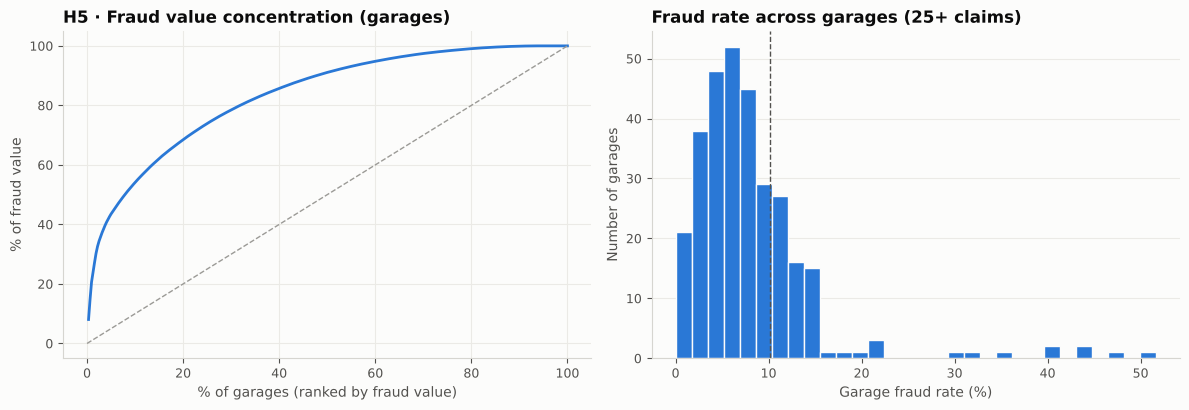

,garage_id,garage_name,city,is_network_garage,claims,frauds,fraud_rate
238,G738,New India Motor Works,Kochi,0,242,125,0.52
96,G596,Prime Automobiles,Jaipur,1,114,53,0.46
86,G586,Balaji Car Care,Bengaluru,0,173,76,0.44
166,G666,New India Motors,Mumbai,0,270,117,0.43
199,G699,Supreme Auto Works,Bengaluru,0,153,61,0.40
93,G593,Royal Motor Works,New Delhi,1,98,39,0.40
15,G515,Royal Auto Works,Kolkata,1,99,35,0.35
84,G584,Sai Auto Works,New Delhi,0,86,28,0.33


In [7]:
garages = q('''
SELECT g.garage_id, g.garage_name, g.city, g.is_network_garage,
       COUNT(*) AS claims, SUM(c.is_fraud) AS frauds,
       SUM(CASE WHEN c.is_fraud = 1 THEN c.total_claim_amount ELSE 0 END) AS fraud_amount
FROM claims c JOIN garages g ON c.garage_id = g.garage_id
GROUP BY g.garage_id''').sort_values("fraud_amount", ascending=False)
garages["fraud_rate"] = garages.frauds / garages.claims
garages["cum_share_fraud_value"] = garages.fraud_amount.cumsum() / garages.fraud_amount.sum()
garages["cum_share_garages"] = np.arange(1, len(garages) + 1) / len(garages)

top5 = garages.cum_share_garages <= 0.05
print(f"Top 5% of garages ({top5.sum()}) account for "
      f"{garages.loc[top5, 'fraud_amount'].sum() / garages.fraud_amount.sum():.0%} of garage-linked fraud value "
      f"and {garages.loc[top5, 'claims'].sum() / garages.claims.sum():.0%} of garage claims.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.plot(100 * garages.cum_share_garages, 100 * garages.cum_share_fraud_value, color=P.BLUE)
ax.plot([0, 100], [0, 100], color=P.GREY, ls="--", lw=1)
ax.set(xlabel="% of garages (ranked by fraud value)", ylabel="% of fraud value", title="H5 · Fraud value concentration (garages)")
ax = axes[1]
eligible = garages[garages.claims >= 25]
ax.hist(100 * eligible.fraud_rate, bins=30, color=P.BLUE, edgecolor="#fcfcfb", linewidth=1)
ax.axvline(BASE_RATE, color=P.INK2, ls="--", lw=1)
ax.set(xlabel="Garage fraud rate (%)", ylabel="Number of garages", title="Fraud rate across garages (25+ claims)")
ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIG + "03_garage_concentration.png")

garages[garages.claims >= 25].sort_values("fraud_rate", ascending=False).head(8)[
    ["garage_id", "garage_name", "city", "is_network_garage", "claims", "frauds", "fraud_rate"]]

In [8]:
agents = q('''
SELECT p.agent_id, a.channel, a.city, COUNT(*) AS claims, AVG(c.is_fraud) AS fraud_rate
FROM claims c JOIN policies p ON c.policy_id = p.policy_id JOIN agents a ON p.agent_id = a.agent_id
GROUP BY p.agent_id HAVING COUNT(*) >= 20''')
hot = agents[agents.fraud_rate > 2 * base.is_fraud.mean()]
print(f"{len(hot)} of {len(agents)} agents ({len(hot)/len(agents):.0%}) run at more than 2x the portfolio fraud rate")
hot.sort_values("fraud_rate", ascending=False)

8 of 150 agents (5%) run at more than 2x the portfolio fraud rate


,agent_id,channel,city,claims,fraud_rate
130,A1130,Agent,Jaipur,176,0.38
116,A1116,Dealer,Kochi,512,0.35
14,A1014,Agent,Bengaluru,201,0.34
98,A1098,Dealer,Bengaluru,165,0.33
51,A1051,Agent,Mumbai,190,0.31
120,A1120,Dealer,Mumbai,207,0.30
115,A1115,Agent,Indore,126,0.28
90,A1090,Agent,Noida,141,0.21


**Read-out: H5 strongly supported.** Fraud isn't spread evenly. A small cluster of garages and agents runs at **3–5× the average**. Two implications:
1. A garage's or agent's *history* is a powerful predictive feature. It has to be computed **point-in-time** (only using investigations already closed) to avoid leakage. See `sql/05_feature_engineering.sql`.
2. Separate from the model, there's a **network-level action**: audit or de-empanel the worst garages and review agent commissions.

## 6. H6: Are fraudulent claims larger relative to the insured value?

Median claim/IDV: fraud 0.164 vs genuine 0.112 | Mann-Whitney p = 1.2e-26


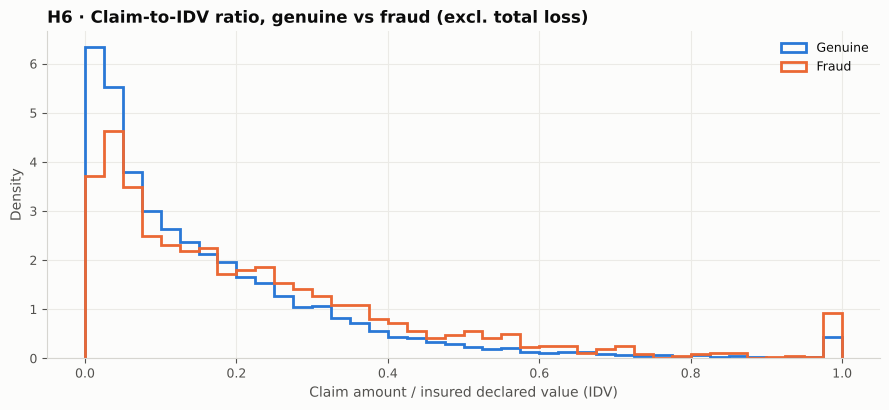

In [9]:
comp = base[(base.idv > 0) & (base.incident_severity != "Total Loss")].copy()
comp["claim_to_idv"] = comp.total_claim_amount / comp.idv
fig, ax = plt.subplots(figsize=(9, 4.2))
bins = np.linspace(0, 1, 41)
for label, color, flag in [("Genuine", P.BLUE, 0), ("Fraud", P.ORANGE, 1)]:
    ax.hist(comp.loc[comp.is_fraud == flag, "claim_to_idv"].clip(upper=1), bins=bins, density=True,
            histtype="step", lw=2, color=color, label=label)
ax.set(xlabel="Claim amount / insured declared value (IDV)", ylabel="Density",
       title="H6 · Claim-to-IDV ratio, genuine vs fraud (excl. total loss)")
ax.legend()
fig.tight_layout(); fig.savefig(FIG + "04_claim_to_idv.png")

u, p = stats.mannwhitneyu(comp.loc[comp.is_fraud == 1, "claim_to_idv"], comp.loc[comp.is_fraud == 0, "claim_to_idv"])
print(f"Median claim/IDV: fraud {comp.loc[comp.is_fraud==1,'claim_to_idv'].median():.3f} vs "
      f"genuine {comp.loc[comp.is_fraud==0,'claim_to_idv'].median():.3f} | Mann-Whitney p = {p:.1e}")

**Read-out: H6 supported.** Fraudulent claims sit noticeably higher relative to the vehicle's insured value, which is consistent with padded repair estimates. The distributions overlap heavily, though, so amount alone can't separate fraud. Signals have to be combined, and that's the case for a model.

## 7. Is today's rules engine good enough?

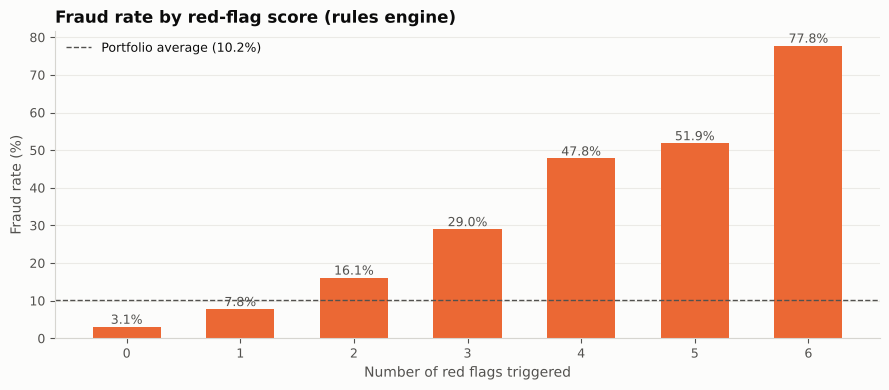

,claims,fraud_rate
red_flag_score,,
0,5560,0.03
1,6186,0.08
2,3606,0.16
3,1196,0.29
4,226,0.48
5,27,0.52
6,9,0.78


In [10]:
rules = base.groupby("red_flag_score").is_fraud.agg(["size", "mean"])
fig, ax = plt.subplots(figsize=(9, 4))
P.bar_rate(ax, rules.index.astype(str), 100 * rules["mean"], "Fraud rate by red-flag score (rules engine)", BASE_RATE, color=P.ORANGE)
ax.set(xlabel="Number of red flags triggered", ylabel="Fraud rate (%)")
fig.tight_layout(); fig.savefig(FIG + "05_rules_engine.png")
rules.rename(columns={"size": "claims", "mean": "fraud_rate"})

**Read-out:** more red flags does mean more fraud, but the score is **coarse**. Hundreds of claims tie at the same score, every flag counts equally, and garage/agent history is ignored. With capacity for only 10% of claims, the SIU can't tell *which* of the tied claims to pick.

## 8. Hypothesis summary
| # | Hypothesis | Result | Evidence |
|---|---|---|---|
| H1 | Early claims riskier | ✅ Supported | 0–30 day claims ~2–3× base rate, p ≪ 0.001 |
| H2 | Late reporting riskier | ✅ Supported | 8+ day delays ~2.5–3× base rate, p ≪ 0.001 |
| H3 | Night, no police report riskier | ✅ Supported | Highest-risk segment of major losses, p ≪ 0.001 |
| H4 | Repeat claimants riskier | ✅ Supported | 2+ prior claims ~3× base rate, p ≪ 0.001 |
| H5 | Concentration in garages/agents | ✅ Strongly supported | Small cluster at 3–5× average |
| H6 | Higher claim vs insured value | ✅ Supported (weak alone) | Shifted, overlapping distributions |

**Next step → `02_modeling.ipynb`:** combine all these signals in an ML model and compare it against the rules engine **on the metric the business cares about: fraud value caught per investigation**.

In [11]:
con.close()